<a href="https://colab.research.google.com/github/joysisilia/PDS-JOYS/blob/main/Regresi_Kota_Denpasar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Topik: Regresi Linear Kota Denpasar (numpy + pandas + matplotlib)
# Variabel bebas  : X1 = PAD, X2 = DBH_PAJAK
# Variabel terikat: Y  = PE
# Visualisasi     : dibuat 3, hanya 2 yang ditampilkan (plt.show)

# Topik: Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# Topik: Konfigurasi variabel
# Variabel bebas  : X1 (PAD), X2 (DBH_PAJAK)
# Variabel terikat: Y (PE)
FILE = "databesarjoy.csv"
KOTA = "Kota Denpasar"
X1 = "PAD"          # variabel bebas 1
X2 = "DBH_PAJAK"    # variabel bebas 2
Y = "PE"            # variabel terikat

# Topik: Membaca data dan memilih satu kota (data series)
df = pd.read_csv(FILE)
d = df[df["Kota"] == KOTA].sort_values("Tahun").reset_index(drop=True)
n = len(d)
print(f"{KOTA}: {n} observasi ({d.Tahun.min()}-{d.Tahun.max()})\n")


# Topik: Fungsi OLS (regresi linear dengan numpy)
def ols(X, y):
    """OLS dengan numpy. X tanpa kolom konstanta."""
    A = np.column_stack([np.ones(len(y)), X])          # tambah intercept
    beta = np.linalg.inv(A.T @ A) @ A.T @ y            # (A'A)^-1 A'y
    yhat = A @ beta
    resid = y - yhat
    k = A.shape[1] - 1                                 # jumlah variabel bebas
    dfr = len(y) - k - 1
    sse = resid @ resid
    sst = ((y - y.mean()) ** 2).sum()
    ssr = sst - sse
    r2 = 1 - sse / sst
    adj = 1 - (1 - r2) * (len(y) - 1) / dfr
    s2 = sse / dfr
    se = np.sqrt(np.diag(s2 * np.linalg.inv(A.T @ A)))
    t = beta / se
    F = (ssr / k) / s2
    try:
        from scipy import stats
        p = 2 * (1 - stats.t.cdf(np.abs(t), dfr))
        pF = 1 - stats.f.cdf(F, k, dfr)
    except Exception:
        p = np.full_like(t, np.nan)
        pF = np.nan
    return dict(beta=beta, se=se, t=t, p=p, r2=r2, adj=adj, F=F, pF=pF,
                dfr=dfr, k=k, yhat=yhat, resid=resid, rmse=np.sqrt(sse / len(y)))


# Topik: Fungsi laporan hasil regresi
def laporan(nama, names, r):
    print("=" * 62)
    print(nama)
    print("=" * 62)
    tab = pd.DataFrame({"Koef": r["beta"], "Std.Err": r["se"],
                        "t-hitung": r["t"], "p-value": r["p"]},
                       index=["Konstanta"] + names)
    print(tab.round(4).to_string())
    print(f"\nR²={r['r2']:.4f} | Adj R²={r['adj']:.4f} | RMSE={r['rmse']:.4f} "
          f"| F={r['F']:.4f} (p={r['pF']:.4f}) | df residual={r['dfr']}\n")


# Topik: Menyiapkan array variabel bebas dan terikat
y = d[Y].to_numpy(float)     # variabel terikat
x1 = d[X1].to_numpy(float)   # variabel bebas 1
x2 = d[X2].to_numpy(float)   # variabel bebas 2

# Topik: Matriks korelasi antar variabel
print("Matriks korelasi:")
print(d[[X1, X2, Y]].corr().round(4), "\n")

# Topik: Model regresi 2D (sederhana) untuk tiap variabel bebas
# Variabel bebas: X1 / X2 | Variabel terikat: Y
r_a = ols(x1, y)
r_b = ols(x2, y)
laporan(f"MODEL 2D (a): {Y} = b0 + b1*{X1}", [X1], r_a)
laporan(f"MODEL 2D (b): {Y} = b0 + b1*{X2}", [X2], r_b)


# Topik: Fungsi plot regresi 2D
def plot_2d(xv, nm, r):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(xv, y, color="tab:blue", s=55, edgecolor="k", label="Data aktual")
    xs = np.linspace(xv.min(), xv.max(), 100)
    ax.plot(xs, r["beta"][0] + r["beta"][1] * xs, color="tab:red", lw=2,
            label=f"Y = {r['beta'][0]:.3f} + {r['beta'][1]:.4f}X\nR² = {r['r2']:.4f}")
    for xi, yi, th in zip(xv, y, d.Tahun):
        ax.annotate(str(th), (xi, yi), textcoords="offset points", xytext=(4, 4), fontsize=7)
    ax.set_xlabel(nm)
    ax.set_ylabel(Y)
    ax.set_title(f"Regresi 2D: {Y} vs {nm} - {KOTA}")
    ax.grid(alpha=.3)
    ax.legend()
    plt.tight_layout()
    return fig


# Topik: Visualisasi 1 - Regresi 2D PAD vs PE (DITAMPILKAN)
# Variabel bebas: PAD | Variabel terikat: PE
fig1 = plot_2d(x1, X1, r_a)
fig1.savefig("visualisasi1_2D_PAD.png", dpi=160)
plt.show()

# Topik: Visualisasi 2 - Regresi 2D DBH_PAJAK vs PE (TIDAK DITAMPILKAN, hanya disimpan)
# Variabel bebas: DBH_PAJAK | Variabel terikat: PE
fig2 = plot_2d(x2, X2, r_b)
fig2.savefig("visualisasi2_2D_DBH_PAJAK.png", dpi=160)
plt.close(fig2)

# Topik: Model regresi 3D (berganda)
# Variabel bebas: PAD dan DBH_PAJAK | Variabel terikat: PE
r3 = ols(np.column_stack([x1, x2]), y)
laporan(f"MODEL 3D: {Y} = b0 + b1*{X1} + b2*{X2}", [X1, X2], r3)

# Topik: Visualisasi 3 - Bidang regresi 3D (DITAMPILKAN)
# Variabel bebas: PAD, DBH_PAJAK | Variabel terikat: PE
b0, b1, b2 = r3["beta"]
g1 = np.linspace(x1.min(), x1.max(), 30)
g2 = np.linspace(x2.min(), x2.max(), 30)
G1, G2 = np.meshgrid(g1, g2)
Z = b0 + b1 * G1 + b2 * G2

fig3 = plt.figure(figsize=(14, 6))
for i, (elev, azim) in enumerate([(22, -60), (15, 35)], 1):
    ax = fig3.add_subplot(1, 2, i, projection="3d")
    ax.plot_surface(G1, G2, Z, alpha=.45, cmap="coolwarm", edgecolor="none")
    above = y >= r3["yhat"]
    ax.scatter(x1[above], x2[above], y[above], c="tab:green", s=45,
               edgecolor="k", label="Data (di atas bidang)")
    ax.scatter(x1[~above], x2[~above], y[~above], c="tab:blue", s=45,
               edgecolor="k", label="Data (di bawah bidang)")
    for xi, zi, yi, yh in zip(x1, x2, y, r3["yhat"]):
        ax.plot([xi, xi], [zi, zi], [yi, yh], color="gray", lw=.8)   # residual
    ax.set_xlabel(X1)
    ax.set_ylabel(X2)
    ax.set_zlabel(Y)
    ax.view_init(elev, azim)
    if i == 1:
        ax.set_title(f"Regresi 3D {KOTA}\nR²={r3['r2']:.3f}, Adj R²={r3['adj']:.3f}")
        ax.legend(loc="upper left", fontsize=7)
plt.tight_layout()
fig3.savefig("visualisasi3_3D.png", dpi=160)
plt.show()

# Topik: Tabel aktual vs prediksi dan simpan hasil
out = pd.DataFrame({"Tahun": d.Tahun, X1: x1, X2: x2, f"{Y}_aktual": y,
                    f"{Y}_prediksi_3D": r3["yhat"].round(4),
                    "Residual": r3["resid"].round(4)})
print(out.to_string(index=False))
out.to_csv("hasil_regresi_denpasar.csv", index=False)

Kota Denpasar: 11 observasi (2014-2024)

Matriks korelasi:
              PAD  DBH_PAJAK      PE
PAD        1.0000     0.5366  0.3695
DBH_PAJAK  0.5366     1.0000  0.4775
PE         0.3695     0.4775  1.0000 

MODEL 2D (a): PE = b0 + b1*PAD
             Koef  Std.Err  t-hitung  p-value
Konstanta  1.8845   1.6925    1.1134   0.2944
PAD        0.0138   0.0116    1.1928   0.2634

R²=0.1365 | Adj R²=0.0406 | RMSE=1.2437 | F=1.4228 (p=0.2634) | df residual=9

MODEL 2D (b): PE = b0 + b1*DBH_PAJAK
             Koef  Std.Err  t-hitung  p-value
Konstanta  0.9359   1.8248    0.5129   0.6204
DBH_PAJAK  0.0503   0.0309    1.6306   0.1374

R²=0.2280 | Adj R²=0.1423 | RMSE=1.1759 | F=2.6588 (p=0.1374) | df residual=9

MODEL 3D: PE = b0 + b1*PAD + b2*DBH_PAJAK
             Koef  Std.Err  t-hitung  p-value
Konstanta  0.6126   2.0507    0.2987   0.7727
PAD        0.0060   0.0136    0.4371   0.6736
DBH_PAJAK  0.0413   0.0383    1.0781   0.3124

R²=0.2461 | Adj R²=0.0576 | RMSE=1.1621 | F=1.3054 (p=0.3231

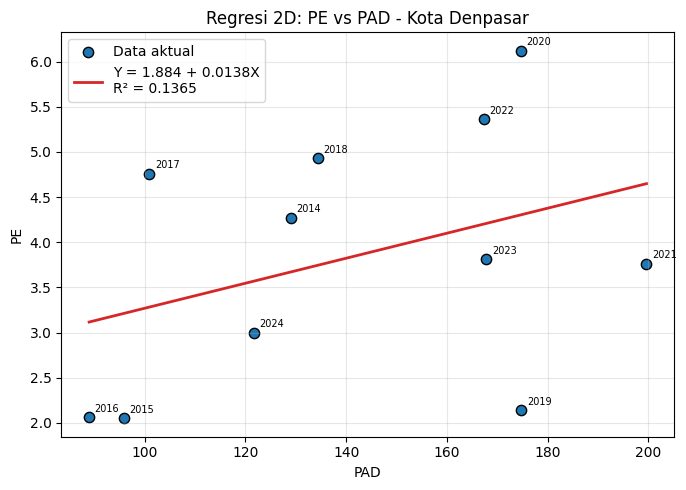

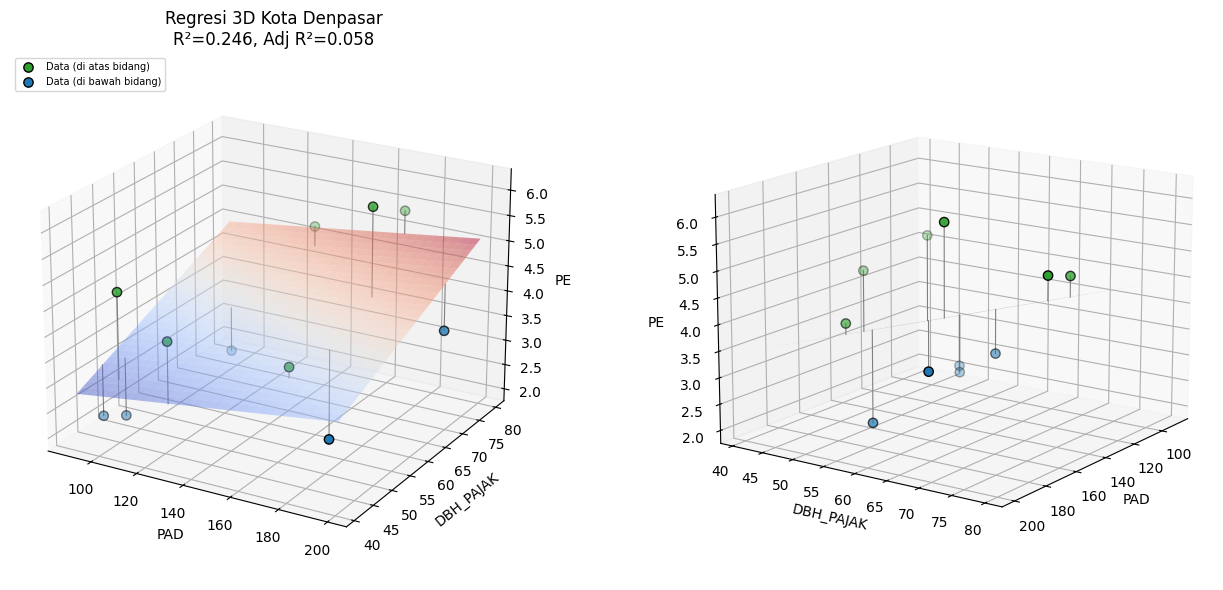

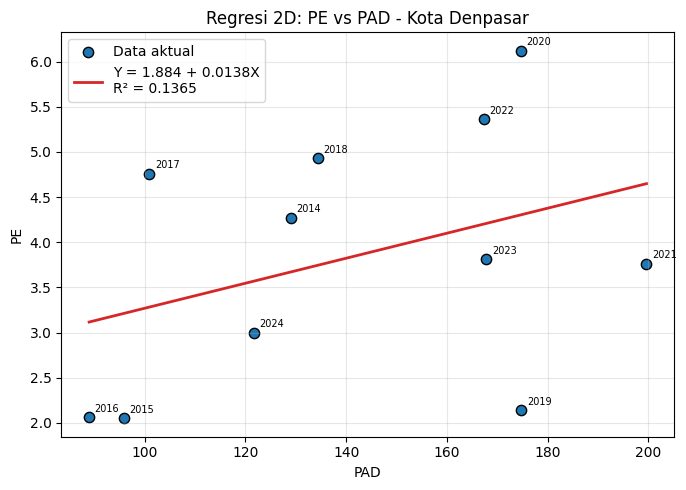

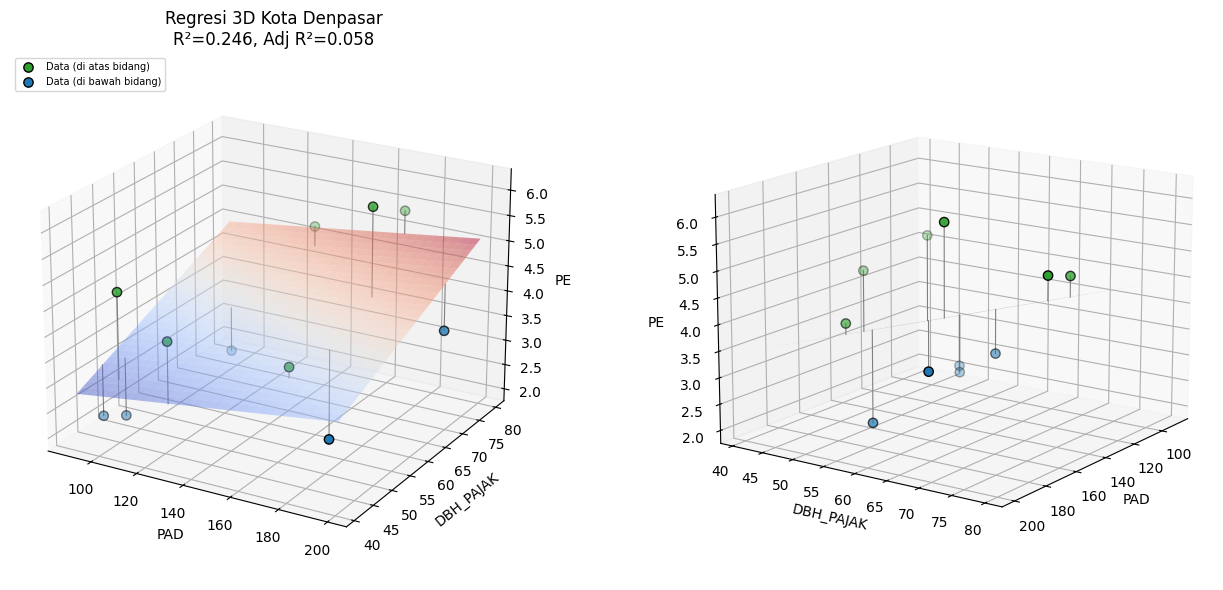

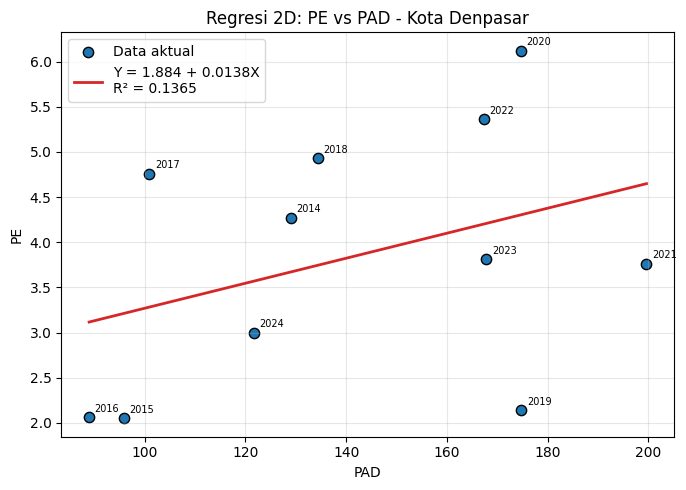

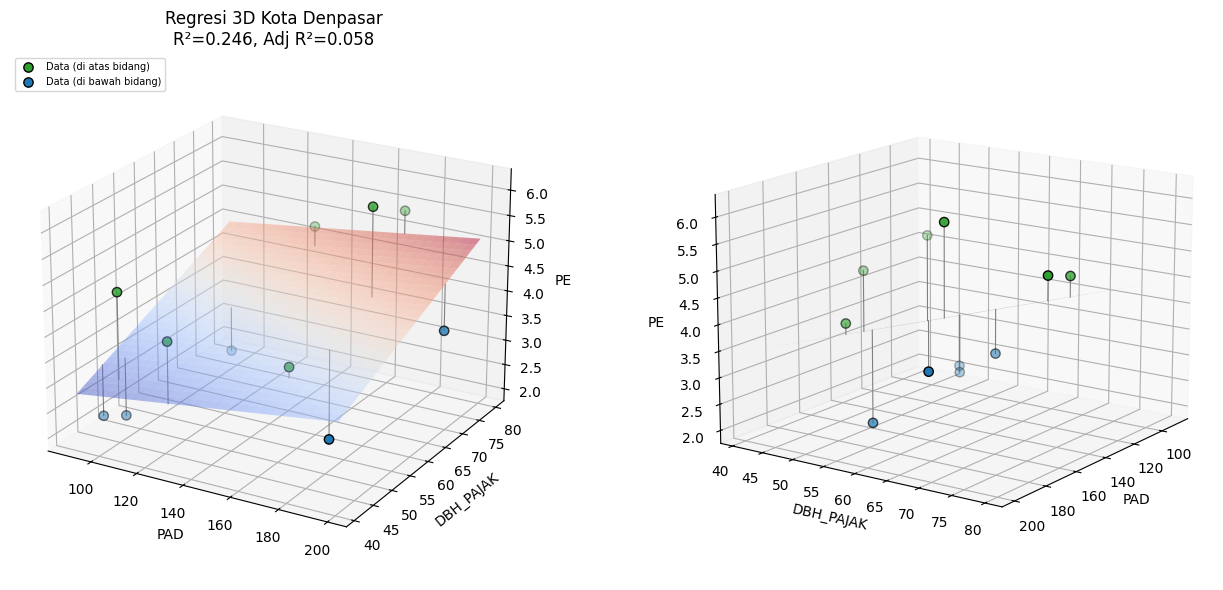

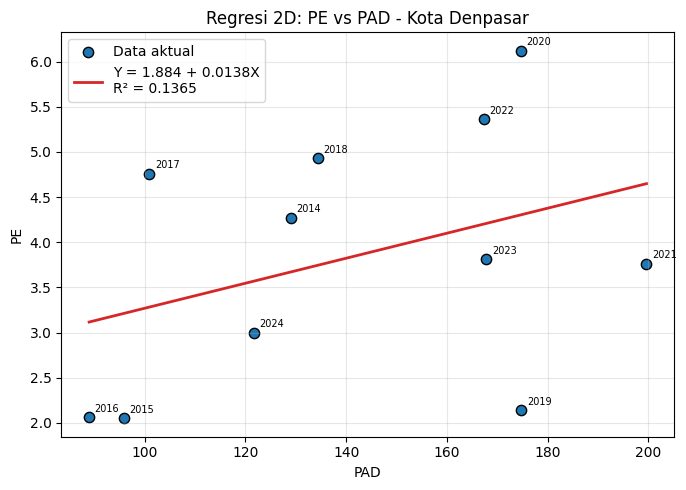

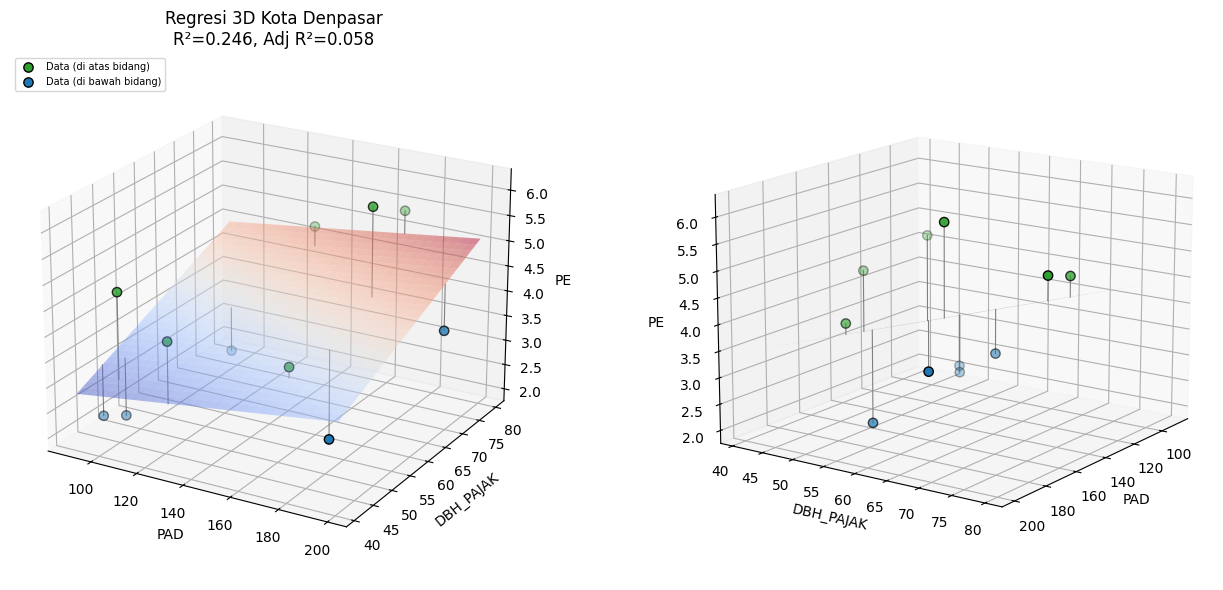

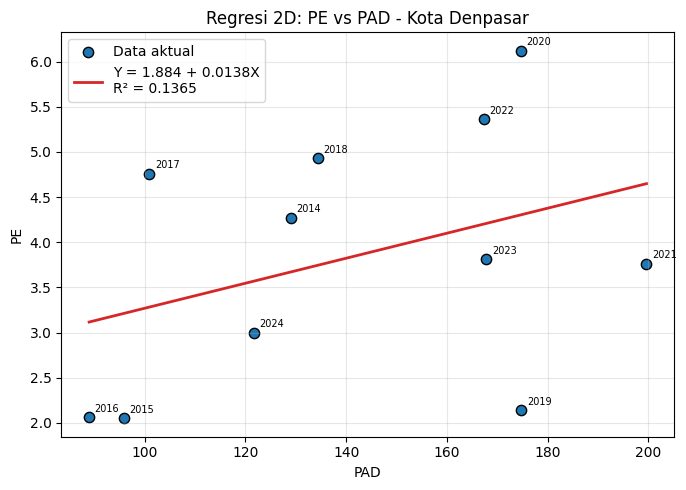

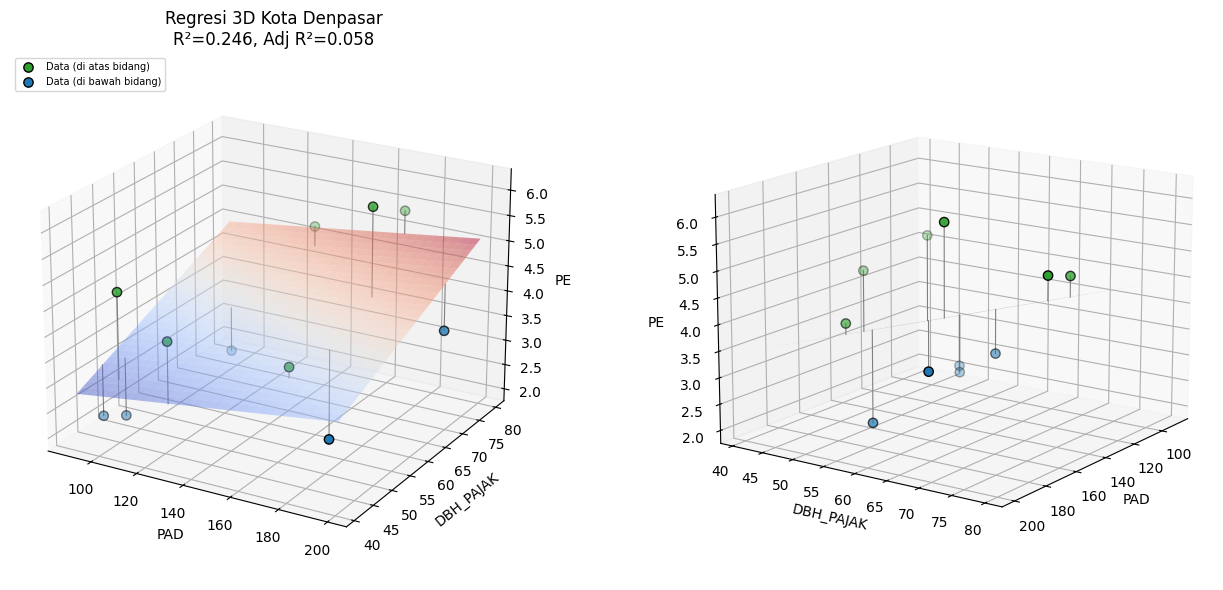

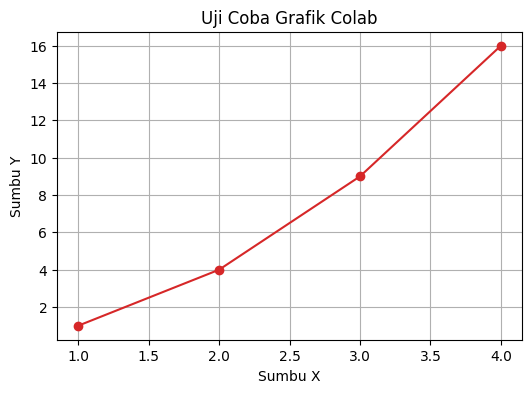

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

# Buat plot sederhana
plt.figure(figsize=(6, 4))
plt.plot([1, 2, 3, 4], [1, 4, 9, 16], marker='o', color='tab:red')
plt.title("Uji Coba Grafik Colab")
plt.xlabel("Sumbu X")
plt.ylabel("Sumbu Y")
plt.grid(True)
plt.show()